# Site figures

Drawn from `results/tables/`. Presentation only.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "figures" / "site"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, RED, GREY, LIGHT = "#2166ac", "#b2182b", "#8c8c8c", "#d9d9d9"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#eeeeee",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def titled(ax, title, sub=None):
    ax.set_title(title, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")


def save(fig, name):
    fig.savefig(OUT / name, facecolor="white")
    plt.show()


In [2]:
CCY = {"6A": "AUD", "6B": "GBP", "6C": "CAD", "6E": "EUR", "6J": "JPY", "6N": "NZD", "6S": "CHF"}

## Implied minus realised volatility by currency

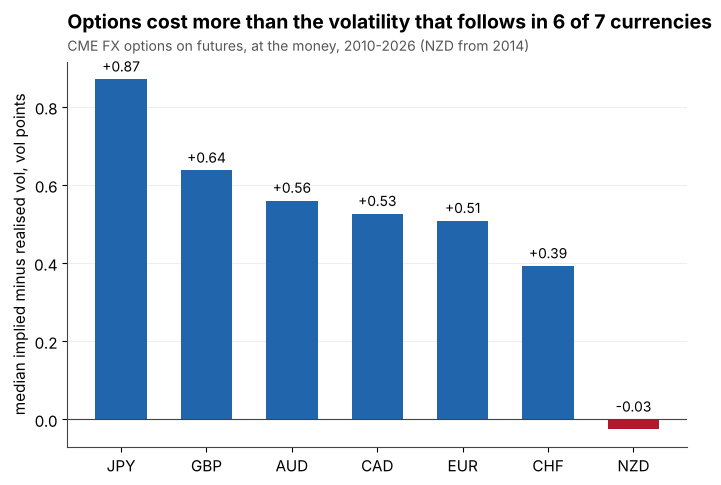

In [3]:
t1 = pd.read_csv(ROOT / "results/tables/table_1_vrp_by_root.csv")
t1["ccy"] = t1.economic_root.map(CCY)
t1 = t1.sort_values("median_vrp_spread", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
cols = [BLUE if v > 0 else RED for v in t1.median_vrp_spread]
bars = ax.bar(t1.ccy, t1.median_vrp_spread, color=cols, width=0.6)
for b, v in zip(bars, t1.median_vrp_spread):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02 if v >= 0 else 0.02, f"{v:+.2f}", ha="center", fontsize=10)
ax.axhline(0, color="#444444", lw=0.8)
ax.set_ylabel("median implied minus realised vol, vol points")
ax.grid(axis="x", visible=False)
titled(ax, "Options cost more than the volatility that follows in 6 of 7 currencies",
       "CME FX options on futures, at the money, 2010-2026 (NZD from 2014)")
save(fig, "premium_by_currency.png")

## The premium year by year

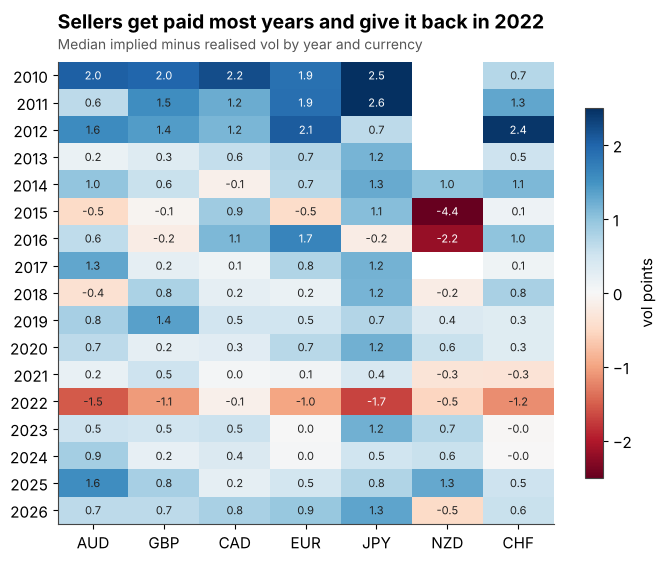

In [4]:
t4 = pd.read_csv(ROOT / "results/tables/table_4_yearly_median_vrp_by_root.csv").set_index("year").rename(columns=CCY)
fig, ax = plt.subplots(figsize=(8, 6))
lim = 2.5
im = ax.imshow(t4.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(t4.shape[1]), t4.columns)
ax.set_yticks(range(t4.shape[0]), t4.index)
ax.grid(False)
for i in range(t4.shape[0]):
    for j in range(t4.shape[1]):
        v = t4.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1.6 else "#222222")
fig.colorbar(im, ax=ax, label="vol points", shrink=0.8)
titled(ax, "Sellers get paid most years and give it back in 2022",
       "Median implied minus realised vol by year and currency")
save(fig, "premium_by_year.png")